# Superdense Coding
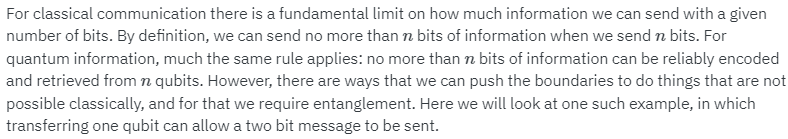

In [2]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector


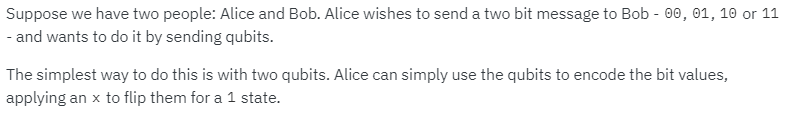

### 1- Using two qubits

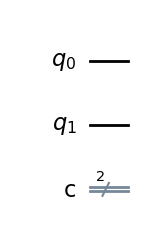

In [3]:
# The message
MESSAGE = '00'

# Alice encodes the message
qc_alice = QuantumCircuit(2, 2)
if MESSAGE[-1]=='1':
    qc_alice.x(0)
if MESSAGE[-2]=='1':
    qc_alice.x(1)
    
qc_alice.draw()

In [4]:
from qiskit import Aer
backend = Aer.get_backend('aer_simulator')

# Bob measures
qc_bob = QuantumCircuit(2,2)
qc_bob.measure([0,1],[0,1])

backend.run(qc_alice.compose(qc_bob)).result().get_counts()

{'00': 1024}

he result Bob gets out will be exactly what Alice put in. This protocol did not involve any entanglement. 

Notice:  
The qc_qlice (a QuantumCiruit object) method **.compose()** will concatenate another QuantumCircuit to it  
This allows Bob to receive the circuit from alice, then perform operations or measurements.

### 2- Using entangled states
One way to insert it would be for Alice to add h and cx gates after encoding the information.

In [5]:
MESSAGE = '00'

qc_alice = QuantumCircuit(2,2)

# Alice encodes the message
if MESSAGE[-1]=='1':
    qc_alice.x(0)
if MESSAGE[-2]=='1':
    qc_alice.x(1)

# then she creates entangled states
qc_alice.h(1)
qc_alice.cx(1,0)

ket = Statevector(qc_alice)
ket.draw(output = 'latex')

<IPython.core.display.Latex object>

When Bob receives these states he needs to disentangle them, by undoing the h and cx. Then he can measure and retrieve the message as before.

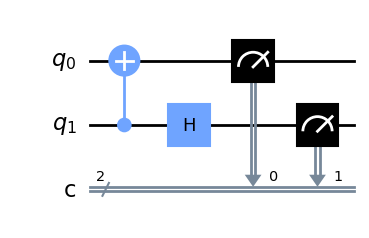

In [6]:
qc_bob = QuantumCircuit(2,2)
# Bob disentangles
qc_bob.cx(1,0)
qc_bob.h(1)
# Then measures
qc_bob.measure([0,1],[0,1])

qc_bob.draw()

So here we used entangled states, but they didn't give us any advantages. For that we need to look at the relationship between these four entangled states.  
This is the "Validation strategy!" were Bob will check one by one, which of the the four possible entangled stated he received.

### 3- Smarth use of entangled states
Look at the relationship between these four entangled states.  
Any Bell state can be obtained from any other Bell state using a X and/or Z gates.  

Alice could send her message by creating an entangled state first, and then changing it using x and z gates to encode the correct message.

In [19]:
MESSAGE = '11'

#Alice creates an entangled pair
qc_alice = QuantumCircuit(2,2)
qc_alice.h(1)
qc_alice.cx(1,0)

qc_alice.barrier()
#Alice encodes the message in one of the qubits
if MESSAGE[-2]=='1':
    qc_alice.z(1)
else:
    qc_alice.id(1)

if MESSAGE[-1]=='1':
    qc_alice.x(1)
else:
    qc_alice.id(1)

qc_alice.barrier()

ket = Statevector(qc_alice)
ket.draw(output ='latex')

<IPython.core.display.Latex object>

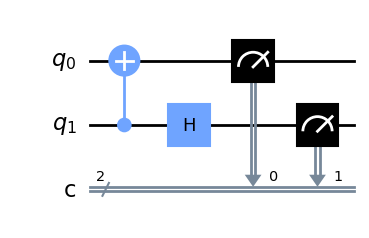

In [20]:
#Since Bob is receiving the same states as before, he doesn't need to change his circuit at all.

qc_bob = QuantumCircuit(2,2)
# Bob disentangles
qc_bob.cx(1,0)
qc_bob.h(1)
# Then measures
qc_bob.measure([0,1],[0,1])

display(qc_bob.draw())


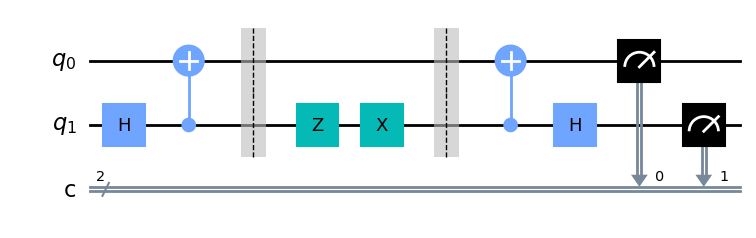

{'11': 1024}

In [21]:
## Bob receives Alice message
qc_composed = qc_alice.compose(qc_bob)

## Whole Protocol
display(qc_composed.draw())

## Bob measures Alice message
backend.run(qc_composed).result().get_counts()